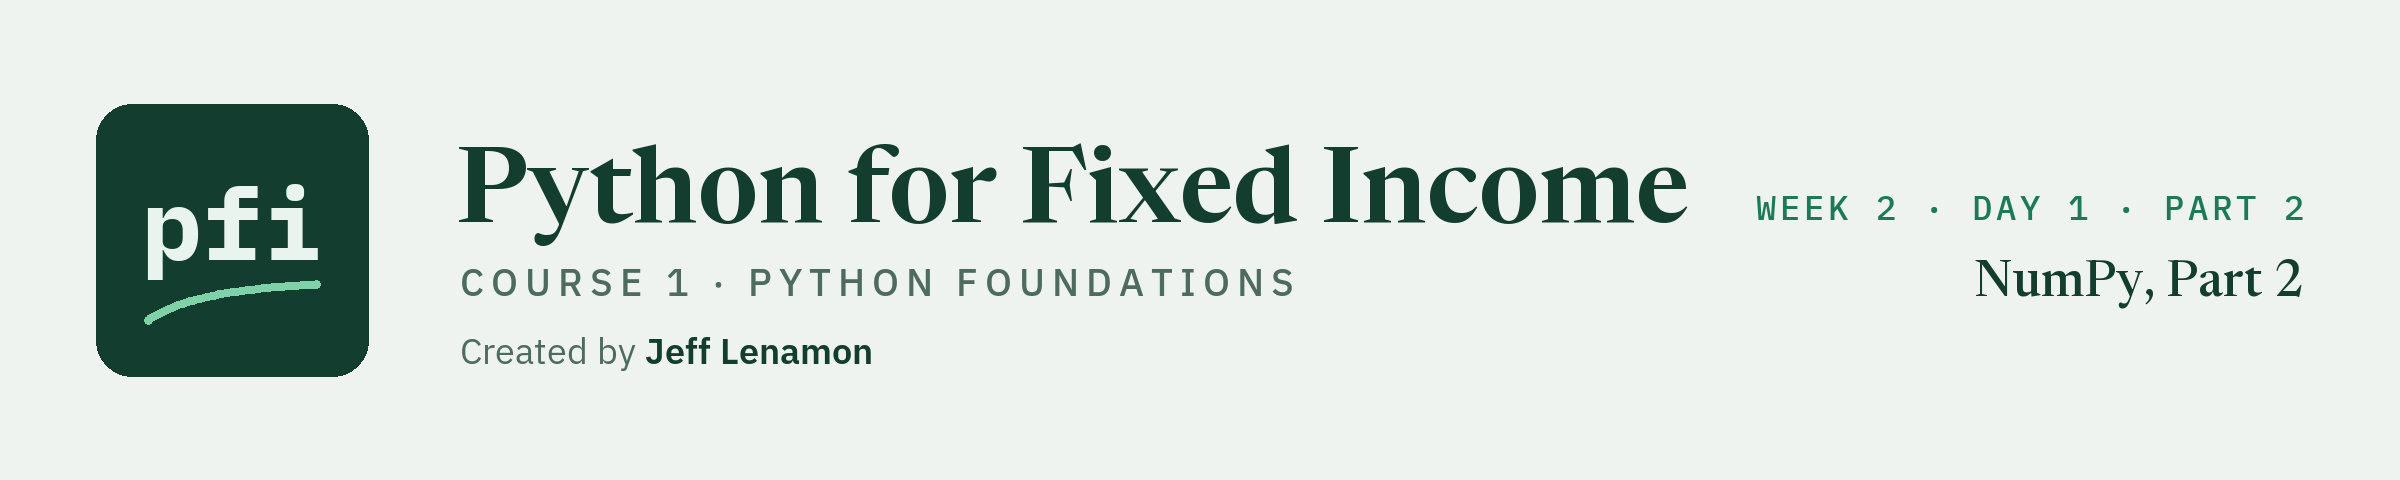

# NumPy, Part 2

Week 2, Day 1, Part 2. Picking out bonds by position and by condition, holding a table in one array, and pricing a bond from its cash flows.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1_part2/06_part2_numpy.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


In Part 1 the desk stopped looping and started calculating: cost, income, and current yield for every bond in one line, then totals, averages, and a weighted average.

Each of those questions used a whole column.

Many desk questions use part of a column: the bonds below par, the high yield names, one row of a table.

This notebook is about reaching those, and then about what arrays are for: pricing a bond from its cash flows.

We stay with the same four bonds.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">QVNE</td><td align="left">5.25</td><td align="left">2033</td><td align="left">98.50</td><td align="left">BBB</td><td align="left">9</td><td align="left">1,500,000</td></tr>
<tr><td align="left">DNMR</td><td align="left">6.125</td><td align="left">2034</td><td align="left">103.25</td><td align="left">BB+</td><td align="left">11</td><td align="left">500,000</td></tr>
<tr><td align="left">PLWK</td><td align="left">4.75</td><td align="left">2031</td><td align="left">95.00</td><td align="left">A-</td><td align="left">7</td><td align="left">750,000</td></tr>
<tr><td align="left">HLVF</td><td align="left">7.50</td><td align="left">2032</td><td align="left">101.00</td><td align="left">B+</td><td align="left">14</td><td align="left">250,000</td></tr>
</table>
<br clear="left">

**Run the cell below first.** It stores what Part 1 built, so this notebook runs on its own.

In [2]:
import numpy as np

# one array per column, in the same bond order
tickers = np.array(['QVNE', 'DNMR', 'PLWK', 'HLVF'])
coupons = np.array([5.25, 6.125, 4.75, 7.5])
prices = np.array([98.5, 103.25, 95.0, 101.0])
faces = np.array([1500000, 500000, 750000, 250000])
scores = np.array([9, 11, 7, 14])

# the annual coupon income of each position and the current yield of each bond, from section 6.3
incomes = faces * coupons / 100
current_yields = coupons / prices * 100

# the three yields from section 6.3, where a price typed in as 0 gave inf. np.inf is that value.
yields_with_zero = np.array([current_yields[0], np.inf, current_yields[2]])

print(f'The desk holds {tickers.size} bonds and {faces.sum():,} of face')

The desk holds 4 bonds and 3,000,000 of face


Nothing here is new.

Part 1 built all of it, one step at a time.

## 6.5 Accessing the Entries of an Array

Indexing and slicing are written the same way on an array as on a list.

One thing behaves differently, and we come to it after the first slice.

Q. Print the price of the first bond and the ticker of the third bond.

In [3]:
# counting starts at 0
print(prices[0])
# index 2 is the third item
print(tickers[2])

98.5
PLWK


Q. Print the coupons of the first two bonds, and the face of the last bond.

In [4]:
# a slice starts at index 0 and stops before index 2
print(coupons[0:2])
# a negative index counts from the end
print(faces[-1])

[5.25  6.125]
250000


5.25 and 6.125 for the slice, and 250,000 for the last face.

A slice of an array is itself an array.

**Predict 1**

A slice of a list is a new list, so a change to the slice leaves the list as it was.

Here is the same thing on an array: take the first two prices as a slice and set the first one to 0.

```
first_two = prices[0:2]
first_two[0] = 0
print(prices)
```

What happens to **prices**?

> A) Nothing. It still starts with 98.5.
>
> B) It changes. It now starts with 0.
>
> C) An error.

Decide, then run the cell.

In [5]:
# take the first two prices as a slice
first_two = prices[0:2]
# change the first value of the slice
first_two[0] = 0
print(prices)

[  0.   103.25  95.   101.  ]


The answer is B, and this is the one difference from a list.

A slice of an array is not a separate copy.

It is a window onto the same numbers.

The change to the slice landed on `prices`: the first price became 0.

Nothing warned us.

Q. Put the real price back, and do the same on a copy of the slice.

In [6]:
# put the real price back
prices[0] = 98.5

# copy() makes a separate array, so this change stays in the copy
first_two_copy = prices[0:2].copy()
first_two_copy[0] = 0
print(prices)

[ 98.5  103.25  95.   101.  ]


`prices` still starts with 98.5.

This is the `.copy()` that Day 3 of week 1 used on a list.

When you want to change a slice and keep the original as it is, slice and then `.copy()`.

A note on how single values are displayed.

When a value is shown as the result of a cell, without `print()`, NumPy shows its type as well.

In [7]:
# the same value, displayed without print()
prices[0]

np.float64(98.5)

`np.float64(98.5)` is the number 98.5, labelled with its NumPy type.

It behaves like any other number.

Use `print()` when you want only the value.

The array has four values, at indexes 0 to 3.

What happens if we ask for index 4?

In [8]:
print(prices[4])

IndexError: index 4 is out of bounds for axis 0 with size 4

An `IndexError`: index 4 is out of bounds for axis 0 with size 4.

The message gives both the index we asked for and the size of the array.

An **axis** is one direction of an array, and this array has only one.

The last valid index is always the size minus one.

A list of positions inside the brackets picks several items at once, as `tickers[order]` did in section 6.4 of Part 1.

Q. Print the tickers of the first and the third bond, and the prices of every other bond.

In [9]:
# the inner brackets are a list of positions
print(tickers[[0, 2]])

# np.arange(0, 4, 2) builds the positions 0 and 2, so every other bond
print(prices[np.arange(0, 4, 2)])

['QVNE' 'PLWK']
[98.5 95. ]


QVNE and PLWK for the tickers, and 98.5 and 95 for the prices.

A list or array of positions is a third way to select, beside a single index and a slice.

The real power of an array is selecting by a condition, not by position.

Q. Which bonds are priced below par?

In [10]:
# a comparison is applied to every value and returns an array of True and False
below_par = prices < 100
print(below_par)

[ True False  True False]


The answer is True, False, True, False.

The first and third bonds are below 100.

An array of True and False values is called a **boolean mask**.

Q. Print the tickers and the prices of the bonds below par.

In [11]:
# a mask inside the brackets keeps the items where the mask is True
print(tickers[below_par])
print(prices[below_par])

['QVNE' 'PLWK']
[98.5 95. ]


QVNE at 98.5 and PLWK at 95.

The mask was made from `prices`, and it works on `tickers` too, because both arrays are in the same bond order.

Q. How many bonds are below par, and how much face do they add up to?

In [12]:
# as on Day 1 of week 1, True counts as 1 and False as 0, so the sum of a mask is a count
print('Bonds below par:', below_par.sum())
print('Face below par:', faces[below_par].sum())

Bonds below par: 2
Face below par: 2250000


2 bonds, holding 2,250,000 of face between them.

Q. Which bonds are high yield, and what is their total annual coupon income? High yield is a rating score of 11 or higher.

In [13]:
# the mask can be written directly inside the brackets
print(tickers[scores >= 11])
print('High yield coupon income:', incomes[scores >= 11].sum())

['DNMR' 'HLVF']
High yield coupon income: 49375.0


DNMR and HLVF, paying 49,375 a year between them.

Q. Which bonds are high yield and priced above 102?

In [14]:
# & means 'and' for masks. Each condition needs its own round brackets.
print(tickers[(scores >= 11) & (prices > 102)])

['DNMR']


Only DNMR passes.

HLVF is high yield, but its price of 101 is not above 102.

Q. Which bonds are high yield, or priced below 96?

In [15]:
# | means 'or' for masks: a bond passes if either condition is True
print(tickers[(scores >= 11) | (prices < 96)])

['DNMR' 'PLWK' 'HLVF']


Three bonds pass: DNMR, PLWK, and HLVF.

PLWK is investment grade and passes on its price alone.

The `|` is the vertical bar, Shift and backslash on a US keyboard.

**Predict 2**

The words `and` and `or` from Day 1 of week 1 work on one True or False at a time.

Here `and` sits between two masks of four values each:

```
print(tickers[(scores >= 11) and (prices > 102)])
```

What do you expect?

> A) DNMR, the same answer as with `&`.
>
> B) An error.
>
> C) An empty array.

Decide, then run the cell.

In [16]:
# the word and between two masks
print(tickers[(scores >= 11) and (prices > 102)])

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

The answer is B. A `ValueError`: the truth value of an array with more than one element is ambiguous.

`and` was handed four answers and does not know which one to use.

For masks, write `&` and `|`.

Q. Section 6.3 produced a yield of `inf` for the bond with the missing price. Which of those three yields are real numbers?

In [17]:
# np.isfinite() is True for an ordinary number, and False for inf and for nan ('not a number')
real = np.isfinite(yields_with_zero)
print(real)
# the mask keeps the real yields only
print(yields_with_zero[real])

[ True False  True]
[5.32994924 5.        ]


True, False, True, and the two real yields, 5.33 and 5.

`np.isfinite()` builds the mask, and the mask does the selecting, as with `<` above.

**Excel side by side.** With a yield in F2, `=ISNUMBER(F2)` is TRUE for a real yield and FALSE for `#DIV/0!`.

Q. Label each bond as 'Premium' or 'Discount'. None of the four is priced at exactly 100.

In [18]:
# np.where(condition, value if True, value if False)
labels = np.where(prices > 100, 'Premium', 'Discount')
print(labels)

['Discount' 'Premium' 'Discount' 'Premium']


Discount, Premium, Discount, Premium.

`np.where()` checks the condition for every bond and picks one of the two values.

In week 1 this took a loop with an `if` and an `else`.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Label each bond</td><td align="left"><code>np.where(prices &gt; 100, 'Premium', 'Discount')</code></td><td align="left"><code>=IF(C2&gt;100, "Premium", "Discount")</code> filled down</td></tr>
<tr><td align="left">Count the bonds below par</td><td align="left"><code>(prices &lt; 100).sum()</code></td><td align="left"><code>=COUNTIF(C2:C5, "&lt;100")</code></td></tr>
<tr><td align="left">Face below par</td><td align="left"><code>faces[prices &lt; 100].sum()</code></td><td align="left"><code>=SUMIF(C2:C5, "&lt;100", B2:B5)</code></td></tr>
<tr><td align="left">Tickers below par</td><td align="left"><code>tickers[prices &lt; 100]</code></td><td align="left"><code>=FILTER(A2:A5, C2:C5&lt;100)</code> in current versions of Excel</td></tr>
</table>
<br clear="left">

A mask can also be used to change values.

Q. The desk wants a what-if: every bond below par is marked up by one point. The real prices must not change.

In [19]:
# copy() makes a separate array, so changes to the what-if leave prices alone
what_if_prices = prices.copy()
# add a point to the bonds below par only
what_if_prices[below_par] = what_if_prices[below_par] + 1

print('What-if:', what_if_prices)
print('Original:', prices)

What-if: [ 99.5  103.25  96.   101.  ]
Original: [ 98.5  103.25  95.   101.  ]


QVNE moves to 99.5 and PLWK to 96.

The other two are untouched, and so is `prices`.

The `copy()` matters.

`what_if_prices = prices` would give the same array a second name, as `what_if_list = price_list` did on Day 3 of week 1, and the change would land on the real prices.

A slice can also stand on the left of an equals sign, to overwrite several positions at once.

Q. In a copy of the prices, set the first two to 99 and 104, and every price from the third on to 100.

In [20]:
edited = prices.copy()
# a list on the right gives one new value to each position of the slice
edited[0:2] = [99.0, 104.0]
# a single number on the right is copied into every position of the slice
edited[2:] = 100

print('Edited:  ', edited)
print('Original:', prices)

Edited:   [ 99. 104. 100. 100.]
Original: [ 98.5  103.25  95.   101.  ]


99, 104, 100, 100, and the original prices are as they were.

#### A Table in One Array

So far each array has been one column.

An array can also have two dimensions: rows and columns, like a block of cells.

Q. Put the coupon, price, and face of the four bonds in a single array, one row per bond.

In [21]:
# a list of lists becomes a 2-D array. Each inner list is one row.
bond_table = np.array([[5.25, 98.5, 1500000],
                       [6.125, 103.25, 500000],
                       [4.75, 95.0, 750000],
                       [7.5, 101.0, 250000]])
print(bond_table)

[[5.2500e+00 9.8500e+01 1.5000e+06]
 [6.1250e+00 1.0325e+02 5.0000e+05]
 [4.7500e+00 9.5000e+01 7.5000e+05]
 [7.5000e+00 1.0100e+02 2.5000e+05]]


The numbers are right but hard to read.

When an array mixes small and large values, NumPy switches to scientific notation: `1.5e+06` is 1.5 times 10 to the power 6, which is 1,500,000.

Excel's Scientific format shows the same number as `1.50E+06`.

Let's turn that off.

In [22]:
# suppress=True tells NumPy to print plain numbers instead of scientific notation
np.set_printoptions(suppress=True)
print(bond_table)

[[      5.25       98.5   1500000.   ]
 [      6.125     103.25   500000.   ]
 [      4.75       95.     750000.   ]
 [      7.5       101.     250000.   ]]


The setting changes how arrays are displayed for the rest of the notebook.

The values stored are not affected.

Q. What is the shape of the table?

In [23]:
print('Dimensions:', bond_table.ndim)
print('Shape:', bond_table.shape)

Dimensions: 2
Shape: (4, 3)


2 dimensions, with a shape of (4, 3): 4 rows and 3 columns.

Rows always come first.

Q. Print the row for DNMR, the second bond.

In [24]:
# one index selects a row
print(bond_table[1])

[     6.125    103.25  500000.   ]


Q. Print the price of DNMR.

In [25]:
# two indexes: row first, then column. Price is column 1.
print(bond_table[1, 1])

103.25


Q. Print the price column for all four bonds.

In [26]:
# a colon on its own means 'every row'
print(bond_table[:, 1])

[ 98.5  103.25  95.   101.  ]


The prices are 98.5, 103.25, 95, and 101.

The colon selects all rows, and the 1 selects the price column.

Q. Print the coupon and price of the first two bonds.

In [27]:
# rows 0 and 1, columns 0 and 1
print(bond_table[0:2, 0:2])

[[  5.25   98.5  ]
 [  6.125 103.25 ]]


Slices work on both dimensions at once.

The result is a smaller table of 2 rows and 2 columns.

Q. What is the average of each column?

In [28]:
# axis=0 works down the rows and gives one result per column
print(bond_table.mean(axis=0))

[     5.90625     99.4375  750000.     ]


5.90625 for the coupon, 99.4375 for the price, and 750,000 for the face.

The first two match the averages from section 6.4.

Without `axis`, `bond_table.mean()` would average all twelve numbers together, coupons and face amounts alike, which means nothing.

The other direction is `axis=1`, which works across the columns and gives one result per row.

It only makes sense when the columns hold the same kind of number.

Here is a table where they do: the two coupon payments each bond makes in a year.

Each is half of the annual income from section 6.3.

In [29]:
# rows are the four bonds, columns are the first and second coupon payment of the year
payments = np.array([[39375.0, 39375.0],
                     [15312.5, 15312.5],
                     [17812.5, 17812.5],
                     [9375.0, 9375.0]])

Q. How much does each bond pay in a year, and how much does the desk receive in each coupon period, the first and the second of each bond's year?

**Predict 3**

`payments` has 4 rows and 2 columns.

How many numbers will `payments.sum(axis=1)` give, and how many will `payments.sum(axis=0)` give?

Decide, then run the cell.

In [30]:
# axis=1 works across the columns: one total per bond
print('Per bond:', payments.sum(axis=1))
# axis=0 works down the rows: one total per coupon period
print('Per coupon period:', payments.sum(axis=0))
# no axis: one total for the whole table
print('Whole table:', payments.sum())

Per bond: [78750. 30625. 35625. 18750.]
Per coupon period: [81875. 81875.]
Whole table: 163750.0


`axis=1` gave four numbers and `axis=0` gave two.

Per bond: 78,750, 30,625, 35,625, and 18,750, the annual incomes from section 6.3.

Per coupon period: 81,875 each time.

The four bonds pay on different dates, so this is a total per period, not per calendar date.

For the whole table: 163,750, the week 1 total.

A way to remember it: the axis you name is the one that disappears.

`axis=0` collapses the rows and leaves one value per column.

`axis=1` collapses the columns and leaves one value per row.

**Excel side by side.** `axis=0` is a `=SUM()` at the bottom of each column.

`axis=1` is a `=SUM()` at the right-hand end of each row.

#### More on Tables

Real data often arrives as one long run of numbers that belongs in a table.

Q. The desk has the closing prices of QVNE, DNMR, and PLWK on four days, typed bond by bond as one run of 12 numbers. Lay them out with one row per bond and one column per day.

In [31]:
# QVNE's four days, then DNMR's four days, then PLWK's four days
flat_prices = np.array([98.5, 98.7, 98.4, 98.9,
                        103.25, 103.0, 102.8, 103.1,
                        95.0, 95.2, 95.4, 95.1])

# reshape((rows, columns)) lays the same numbers out in a grid, filling one row at a time
price_grid = flat_prices.reshape((3, 4))
print(price_grid)
print('Shape:', price_grid.shape)

[[ 98.5   98.7   98.4   98.9 ]
 [103.25 103.   102.8  103.1 ]
 [ 95.    95.2   95.4   95.1 ]]
Shape: (3, 4)


Three rows, four columns.

The numbers have not changed, only how they are laid out.

`flat_prices` itself is unchanged.

**Excel side by side.** In Microsoft 365, with the 12 numbers in A1:L1, `=WRAPROWS(A1:L1, 4)` spills the same grid, filling one row at a time.

What if the grid is the wrong size?

In [32]:
# 12 numbers cannot fill 3 rows of 5
flat_prices.reshape((3, 5))

ValueError: cannot reshape array of size 12 into shape (3,5)

A `ValueError`: cannot reshape array of size 12 into shape (3,5).

The rows times the columns must equal the number of values: 3 times 4 is 12, and 3 times 5 is 15.

Q. Turn the grid around so that each row is a day and each column is a bond.

In [33]:
# .T is the transpose: rows become columns and columns become rows
print(price_grid.T)
print('Shape:', price_grid.T.shape)

[[ 98.5  103.25  95.  ]
 [ 98.7  103.    95.2 ]
 [ 98.4  102.8   95.4 ]
 [ 98.9  103.1   95.1 ]]
Shape: (4, 3)


Four rows, three columns.

A table of prices over time usually has one row per day, so `.T` is how a grid like this one is turned the right way up.

Q. Overwrite part of a table. In a copy of the grid, set DNMR's last two prices to 100.

In [34]:
grid_copy = price_grid.copy()
# row 1 is DNMR, and the slice 2: is the last two columns
grid_copy[1, 2:] = 100
print(grid_copy)

[[ 98.5   98.7   98.4   98.9 ]
 [103.25 103.   100.   100.  ]
 [ 95.    95.2   95.4   95.1 ]]


DNMR's last two prices are 100, and every other price is as it was.

Q. Take a window of the first two bonds' first two days and set it to 0. What happens to the copy?

In [35]:
# a slice of a table is a window onto it, just as it is for one column
window = grid_copy[0:2, 0:2]
# [:] means every position in the window
window[:] = 0
print(grid_copy)
print('price_grid is unchanged:', price_grid[0, 0])

[[  0.    0.   98.4  98.9]
 [  0.    0.  100.  100. ]
 [ 95.   95.2  95.4  95.1]]
price_grid is unchanged: 98.5


The top left two-by-two block of `grid_copy` is now 0, because a slice shares its numbers with the table it came from.

We changed the copy, so `price_grid` still starts with 98.5.

Q. What was the market value of the three-bond book on each of the four days? The desk holds 1,500,000 of QVNE, 500,000 of DNMR, and 750,000 of PLWK.

In [36]:
three_faces = faces[:3]

# @ is matrix multiplication: each day's column of prices is multiplied by the faces and added up
book_values = three_faces @ price_grid / 100
print(book_values)

# the first day by hand, to check the @
print(np.sum(three_faces * price_grid[:, 0] / 100))

[2706250. 2709500. 2705500. 2712250.]
2706250.0


Four values, one per day, about 2.7 million each.

The first day by hand, face times price over 100, added up, gives the same figure as the first value above.

`@` multiplies a row of numbers by each column of a table and adds up, which is exactly "multiply the faces by the prices and sum".

It is what a SUMPRODUCT does on each day's column of prices.

**Excel side by side.** With the faces in B2:B4 and one day's prices in C2:C4, the value is `=SUMPRODUCT($B$2:$B$4, C2:C4)/100`, filled to the right for each day.

With the four days in C2:F4, `=MMULT(TRANSPOSE(B2:B4), C2:F4)/100` gives all four values in one step, and `=TRANSPOSE()` on its own is `.T`.

One special table is worth knowing.

The identity matrix has 1 on the diagonal and 0 everywhere else.

Q. What does multiplying the faces by an identity matrix do?

In [37]:
# np.eye(3) is the 3 by 3 identity matrix
identity = np.eye(3)
print(identity)

# anything multiplied by the identity comes back unchanged
print(three_faces @ identity)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[1500000.  500000.  750000.]


The faces come back unchanged: 1,500,000, 500,000, and 750,000.

The identity is the matrix version of multiplying by 1, which makes it a quick test that matrix code is wired correctly.

In Excel, `=MUNIT(3)` spills the same 3 by 3 table.

Q. Build a grid of zeros with 2 rows and 3 columns.

In [38]:
# np.zeros() and np.ones() also accept a shape in brackets, rows first
print(np.zeros((2, 3)))

[[0. 0. 0.]
 [0. 0. 0.]]


## 6.6 Pricing a Bond From Its Cash Flows

Here is a calculation that shows what arrays are for.

The price of a bond is the present value of its cash flows: each payment divided by one plus the yield per period, raised to the number of periods until it is paid.

We price QVNE, the 5.25% bond, per 100 of face.

To keep the arithmetic clean we make three assumptions and state them plainly:

* **Whole periods.** The bond has exactly 7 years to maturity, which is 14 semiannual coupon periods.
* **Semiannual compounding.** The yield is quoted as an annual rate and half of it applies to each period.
* **Settlement on a coupon date.** No coupon has started to accrue, so there is no accrued interest.

Real bonds settle between coupon dates and need day counts and accrued interest.

The full treatment of price and yield belongs to the Bond Math course.

This section is a preview of what arrays make easy.

Q. Number the 14 coupon periods.

In [39]:
# the terms of the bond
coupon = 5.25
years = 7
periods_per_year = 2

# period numbers 1 to 14
periods = np.arange(1, years * periods_per_year + 1)
print(periods)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14]


Q. Build the cash flows per 100 of face: a coupon every period, and the 100 of principal with the last one.

In [40]:
# each semiannual coupon is half of the annual coupon
cash_flows = np.ones(periods.size) * coupon / periods_per_year
# the principal is repaid with the final coupon
cash_flows[-1] = cash_flows[-1] + 100
print(cash_flows)

[  2.625   2.625   2.625   2.625   2.625   2.625   2.625   2.625   2.625
   2.625   2.625   2.625   2.625 102.625]


Thirteen payments of 2.625 and a final payment of 102.625.

`np.ones()` from section 6.2 gives the constant coupon, and a negative index changes the last entry only.

Q. The yield is 5.51 percent. Build the discount factor for each period.

In [41]:
# the yield as a decimal, per period
yield_pct = 5.51
yield_per_period = yield_pct / 100 / periods_per_year

# ** raises to a power. One discount factor for each period number.
discount_factors = 1 / (1 + yield_per_period) ** periods
print(np.round(discount_factors, 4))

[0.9732 0.9471 0.9217 0.897  0.8729 0.8495 0.8268 0.8046 0.783  0.762
 0.7416 0.7217 0.7024 0.6835]


The first discount factor is 0.9732 and the last is 0.6835.

A dollar paid in six months is worth about 97 cents today at this yield, and a dollar paid in 7 years about 68 cents.

`periods` is an array, so the power is taken for all 14 periods at once.

Q. What is each cash flow worth today, and what is the price of the bond?

In [42]:
# present value of each cash flow
present_values = cash_flows * discount_factors
print(np.round(present_values, 4))

# the price is the sum of the present values
qvne_price = present_values.sum()
print('Price of QVNE at a yield of 5.51 percent:', round(qvne_price, 4))

[ 2.5546  2.4861  2.4195  2.3546  2.2915  2.23    2.1702  2.1121  2.0554
  2.0003  1.9467  1.8945  1.8437 70.1474]
Price of QVNE at a yield of 5.51 percent: 98.5067


The price is 98.5067, or 98.51 to the cent.

That is the 98.50 in the desk's table, to within a cent.

Under these assumptions, a price of 98.50 and a yield of about 5.51 percent are two ways of saying the same thing.

The final payment is worth 70.1474 today, so most of the bond's value sits in the last cash flow.

The whole calculation is three lines of array arithmetic: cash flows, discount factors, and the sum of their product.

There is no loop.

Q. Show each payment next to what it is worth today. This is another chart to run and read.

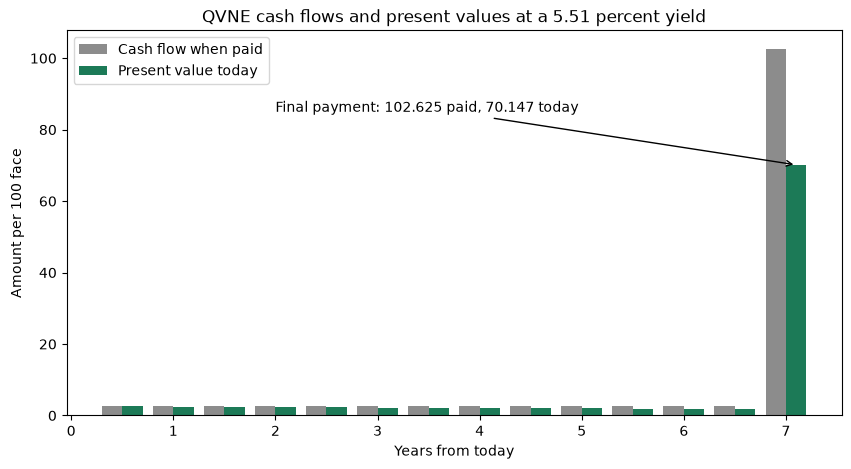

In [43]:
import matplotlib.pyplot as plt

# the time of each payment in years: period 1 is 0.5 years, period 14 is 7 years
payment_years = periods / periods_per_year
bar_width = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
# grey bars are the cash flows as paid, green bars are the same payments worth less today
ax.bar(payment_years - bar_width / 2, cash_flows, bar_width, color='#8c8c8c', label='Cash flow when paid')
ax.bar(payment_years + bar_width / 2, present_values, bar_width, color='#1c7a57', label='Present value today')
# point at the final payment, where the principal is repaid
ax.annotate(f'Final payment: {cash_flows[-1]:.3f} paid, {present_values[-1]:.3f} today',
            xy=(payment_years[-1] + bar_width / 2, present_values[-1]), xytext=(2.0, 85), arrowprops=dict(arrowstyle='->'))
ax.set_title('QVNE cash flows and present values at a 5.51 percent yield')
ax.set_xlabel('Years from today')
ax.set_ylabel('Amount per 100 face')
ax.legend(loc='upper left')
plt.show()

Thirteen small bars for the coupons and one tall bar at 7 years for the principal.

The green bar is always a little shorter than the grey one beside it, and the gap grows with time: the longer a payment takes to arrive, the less it is worth today.

The tall final bar is why most of the bond's value sits in its last payment.

Q. Put the calculation in a function, and use it to price the bond at a yield equal to its coupon.

**Predict 4**

The next cell prices QVNE at a yield of 5.51 percent and again at 5.25 percent, which is its coupon.

At 5.51 the price is 98.5067.

What will the price be at a yield of 5.25: above 100, below 100, or exactly 100?

Decide, then run the cell.

In [44]:
def price_from_yield(coupon, years, yield_pct):
    """
    Take an annual coupon in percent, a whole number of years to maturity,
    and an annual yield in percent,
    and return the price per 100 of face.
    Assumes semiannual coupons and settlement on a coupon date.
    """
    periods = np.arange(1, years * 2 + 1)
    cash_flows = np.ones(periods.size) * coupon / 2
    cash_flows[-1] = cash_flows[-1] + 100
    discount_factors = 1 / (1 + yield_pct / 100 / 2) ** periods
    return (cash_flows * discount_factors).sum()


print('Price at a yield of 5.51:', round(price_from_yield(5.25, 7, 5.51), 4))
print('Price at a yield of 5.25:', round(price_from_yield(5.25, 7, 5.25), 4))

Price at a yield of 5.51: 98.5067
Price at a yield of 5.25: 100.0


The answer is exactly 100.

At a yield of 5.51 the function returns 98.5067, the same as above.

At a yield of 5.25, equal to the coupon, the price is 100.

A bond priced at a yield equal to its coupon is worth par, which is a good check on any pricing code.

**Excel side by side.** With the 14 cash flows in B2:B15 and the 14 discount factors in C2:C15, the price is `=SUMPRODUCT(B2:B15, C2:C15)`.

Excel can also reach it in one step with `=PV(5.51%/2, 14, -2.625, -100)`.

Excel's `PRICE` function handles real settlement and maturity dates, and is covered in the Bond Math course.

Q. A colleague discounts continuously instead of twice a year, treating the yield as compounding all the time. The discount factor for a payment `t` years away is e to the power of minus the yield times `t`. What price does that give?

In [45]:
# np.exp(x) is e raised to the power x, for every value in the array at once
continuous_factors = np.exp(-yield_pct / 100 * payment_years)
continuous_price = (cash_flows * continuous_factors).sum()

print('Last discount factor, twice a year:', round(discount_factors[-1], 4))
print('Last discount factor, continuous:  ', round(continuous_factors[-1], 4))
print('Price, twice a year:', round(qvne_price, 4))
print('Price, continuous:  ', round(continuous_price, 4))

Last discount factor, twice a year: 0.6835
Last discount factor, continuous:   0.68
Price, twice a year: 98.5067
Price, continuous:   98.0718


The continuous price is slightly lower than the twice-a-year price.

The same quoted yield means a different cash value when the compounding convention is different, so a yield is only meaningful together with its convention.

In Excel the continuous discount factor is `=EXP(-5.51%*A2)` for a time in A2.

## 6.7 Saving and Loading Arrays

Arrays live in memory and are gone when the notebook is closed.

NumPy can write an array to a file and read it back.

A file name with no folder in front lands in the working directory, as on Day 2 of week 1.

Q. Save the **prices** array to a file, then load it into a new variable.

In [46]:
# np.save() writes one array to a file in NumPy's own format, with the extension .npy
np.save('desk_prices.npy', prices)

# np.load() reads it back
loaded_prices = np.load('desk_prices.npy')
print(loaded_prices)

[ 98.5  103.25  95.   101.  ]


The four prices came back exactly as they were saved.

A `.npy` file is quick and exact.

Excel cannot open it.

It is meant for reading back into NumPy.

Q. Save **bond_table** as a CSV file that Excel can open.

In [47]:
# np.savetxt() writes plain text. delimiter=',' puts a comma between the columns.
# fmt='%.3f' is a format code. % starts it, .3 means 3 decimal places, and f means a float, as in an f-string.
# header adds a first line of column names, and comments='' stops NumPy putting a # in front of it.
np.savetxt('desk_bond_table.csv', bond_table, delimiter=',', fmt='%.3f',
           header='coupon,price,face', comments='')

Let's look at what was written, using the file reading from week 1.

In [48]:
# open the file and print its contents
with open('desk_bond_table.csv', 'r', encoding='utf-8') as file:
    print(file.read())

coupon,price,face
5.250,98.500,1500000.000
6.125,103.250,500000.000
4.750,95.000,750000.000
7.500,101.000,250000.000



A header line and four rows of numbers separated by commas.

This is an ordinary CSV file.

Double-click it and it opens in Excel.

The same kind of file comes out of Excel with Save As and the file type CSV.

The tickers are not in it, because an array holds one type.

Q. Load the CSV file back into an array.

In [49]:
# np.loadtxt() reads a text file of numbers. skiprows=1 skips the header line.
loaded_table = np.loadtxt('desk_bond_table.csv', delimiter=',', skiprows=1)
print(loaded_table)

[[      5.25       98.5   1500000.   ]
 [      6.125     103.25   500000.   ]
 [      4.75       95.     750000.   ]
 [      7.5       101.     250000.   ]]


Q. Is the loaded table the same as the original?

In [50]:
# np.array_equal() returns True when two arrays have the same shape and the same values
print(np.array_equal(loaded_table, bond_table))

True


The answer is True.

Every coupon, price, and face survived the round trip.

Had we written fewer decimal places than the data has, for example `fmt='%.2f'` with a coupon of 6.125, the file would hold a rounded number and this check would say False.

Q. Save the prices and the faces together in one file, and read both back.

In [51]:
# np.savez() puts several arrays in one .npz file. The names on the left of = become the labels.
np.savez('desk_arrays.npz', prices=prices, faces=faces)

# np.load() on an .npz file opens it like a folder of arrays. 'with' closes it afterwards.
with np.load('desk_arrays.npz') as saved:
    print('Names inside:', saved.files)
    print('prices:', saved['prices'])
    print('faces:', saved['faces'])

Names inside: ['prices', 'faces']
prices: [ 98.5  103.25  95.   101.  ]
faces: [1500000  500000  750000  250000]


Two names inside the file, `prices` and `faces`, and each array comes back by its name.

`np.save()` keeps one array per file.

`np.savez()` keeps as many as you like in one.

Printing the opened file without picking a name shows only an object, not the numbers.

Always pick an array by name, as above.

The lesson is done with these files, so let's remove them.

In [52]:
# os is the module from Day 2 of week 1 for working with files and folders
import os

os.remove('desk_prices.npy')
os.remove('desk_bond_table.csv')
os.remove('desk_arrays.npz')

print('desk_prices.npy still there:', os.path.exists('desk_prices.npy'))
print('desk_bond_table.csv still there:', os.path.exists('desk_bond_table.csv'))
print('desk_arrays.npz still there:', os.path.exists('desk_arrays.npz'))

desk_prices.npy still there: False
desk_bond_table.csv still there: False
desk_arrays.npz still there: False


All three are gone, and the folder is as it was before the lesson.

## You Can Now

By the end of this notebook, you can:

* Pick out bonds by a position, a slice, or a condition such as below par or high yield, and label them with `np.where()`
* Change a slice or a filtered part of an array on a `.copy()`, so that the original stays as it was
* Hold a table in one array and work down its columns with `axis=0` or across its rows with `axis=1`
* Lay a run of numbers out as a table with `reshape`, turn it with `.T`, and value a book across several days with `@`
* Price a bond from its cash flows and discount factors under simple assumptions, and see each payment next to its present value
* Save one array or several to a file, load them back, and check that they arrived intact

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk holds three different bonds.

Use what you learned above to answer its questions.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports NumPy, stores the three bonds as the arrays `tickers`, `coupons`, `prices`, `faces`, and `scores`, and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [53]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's three bonds, one array per column
tickers = np.array(['TRNW', 'OSMC', 'CLDB'])
coupons = np.array([4.375, 5.0, 8.25])
prices = np.array([96.25, 100.0, 104.5])
faces = np.array([2000000, 1250000, 500000])
scores = np.array([6, 10, 15])

### Exercise 1

Q. Use a boolean mask to find the tickers of the bonds priced below par, and the total face held in investment grade bonds (a score of 10 or lower). Then use `np.where()` to label each bond 'Below par' when its price is under 100 and 'Par or above' otherwise. Store the answers in **ex1_below_par**, **ex1_ig_face**, and **ex1_labels**.

In [54]:
ex1_below_par = ...
ex1_ig_face = ...
ex1_labels = ...

In [55]:
check('Exercise 1 below par', ex1_below_par, np.array(['TRNW']))
check('Exercise 1 investment grade face', ex1_ig_face, 3250000)
check('Exercise 1 labels', ex1_labels, np.array(['Below par', 'Par or above', 'Par or above']))

Exercise 1 below par: not attempted yet
Exercise 1 investment grade face: not attempted yet
Exercise 1 labels: not attempted yet


### Exercise 2

The second desk's risk system wants the holdings as one table in a file, not as separate columns.

Q. Build a 2-D array with one row per bond and three columns: coupon, price, and face held. Store it in **ex2_table**. Find the average of each column and store it in **ex2_column_averages**. Then save the table to a file named `second_desk_table.csv` with `np.savetxt()`, using a comma as the delimiter and three decimal places, load it back with `np.loadtxt()`, and store the loaded array in **ex2_loaded**.

In [56]:
ex2_table = ...
ex2_column_averages = ...
ex2_loaded = ...

In [57]:
check('Exercise 2 table', ex2_table, np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))
check('Exercise 2 column averages', ex2_column_averages, np.array([5.875, 100.25, 1250000.0]))
check('Exercise 2 loaded', ex2_loaded, np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))

Exercise 2 table: not attempted yet
Exercise 2 column averages: not attempted yet
Exercise 2 loaded: not attempted yet


### Exercise 3

The second desk's closing prices for TRNW, OSMC, and CLDB on three days arrive as one run of 9 numbers, bond by bond: 96.25, 96.5, 96.0, then 100.0, 100.2, 100.1, then 104.5, 104.0, 104.25.

Q. Lay the prices out as a grid with one row per bond and one column per day, and store it in **ex3_grid**. Use `@` to find the market value of the whole book on each day, and store it in **ex3_book_values**. Then find the log return of the book from the first day to the last day, and store it in **ex3_log_return**.

In [58]:
ex3_grid = ...
ex3_book_values = ...
ex3_log_return = ...

In [59]:
check('Exercise 3 grid', ex3_grid, np.array([[96.25, 96.5, 96.0], [100.0, 100.2, 100.1], [104.5, 104.0, 104.25]]))
check('Exercise 3 book values', ex3_book_values, np.array([3697500.0, 3702500.0, 3692500.0]))
check('Exercise 3 log return', ex3_log_return, -0.00135318018)

Exercise 3 grid: not attempted yet
Exercise 3 book values: not attempted yet
Exercise 3 log return: not attempted yet


### Exercise 4

OSMC has a 5 percent coupon.

Give it exactly 5 years to maturity and price it per 100 of face at a yield of 6 percent, with the three assumptions of section 6.6: whole periods, semiannual compounding, and settlement on a coupon date.

Q. Build the cash flows in **ex4_cash_flows**, the discount factors in **ex4_discount_factors**, and the price in **ex4_price**.

In [60]:
ex4_cash_flows = ...
ex4_discount_factors = ...
ex4_price = ...

In [61]:
check('Exercise 4 last cash flow', None if ex4_cash_flows is ... else ex4_cash_flows[-1], 102.5)
check('Exercise 4 first discount factor', None if ex4_discount_factors is ... else ex4_discount_factors[0], 1 / 1.03)
check('Exercise 4 price', ex4_price, 95.73489858)

Exercise 4 last cash flow: not attempted yet
Exercise 4 first discount factor: not attempted yet
Exercise 4 price: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that prices a bond from its yield, with the assumptions of section 6.6.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the price of OSMC at a yield of 6 percent yourself in Exercise 4. Then run the code. Does it agree with you?

In [62]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def ai_price(coupon, years, yield_pct):
    """
    Take an annual coupon in percent, a whole number of years to maturity,
    and an annual yield in percent,
    and return the price per 100 of face.
    Assumes semiannual coupons and settlement on a coupon date.
    """
    periods = np.arange(1, years * 2 + 1)
    cash_flows = np.ones(periods.size) * coupon / 2
    cash_flows[-1] = cash_flows[-1] + 100
    discount_factors = 1 / (1 + yield_pct / 100) ** periods
    return (cash_flows * discount_factors).sum()


ex5_price = ai_price(5.0, 5, 6.0)
print(f'The price of OSMC at a yield of 6 percent is {round(ex5_price, 4)}')

The price of OSMC at a yield of 6 percent is 74.2397


Q. Find the bug and fix the code in the cell above, so that **ex5_price** holds the right answer.

In [63]:
check('Exercise 5', ex5_price, 95.73489858)

Exercise 5: not yet. You have 74.23969532004853


When you are finished, run this cell to remove the file that Exercise 2 created.

In [64]:
import os

# remove the file from Exercise 2, if it was created
if os.path.exists('second_desk_table.csv'):
    os.remove('second_desk_table.csv')

print('second_desk_table.csv still there:', os.path.exists('second_desk_table.csv'))

second_desk_table.csv still there: False


## Congratulations!

You have finished NumPy, and it was a long day.

You picked bonds out of an array with a mask, held a table in one array, and valued a book across four days in a single line.

Then you priced a bond from its cash flows with no loop at all, and the number you got was the price on the desk's own sheet.

That is real fixed income work, and you wrote every line of it.

Next is pandas: Series and DataFrames. pandas puts names on the rows and columns of these arrays, and the portfolio grows to two hundred bonds.